In [163]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Loading the ledger and labels, and joining the data

The anomaly ledger stores one row per journal line. The labels file stores one row per journal entry. The notebook joins them using `entry_id`, so each ledger line can be associated with its entry's anomaly label.

The merge is checked with `validate="many_to_one"`. This means several journal lines may have the same entry ID, but those lines must all match one label. The assertion checks that every ledger line received a label.


In [164]:
ledger_path = Path("../data/raw/ledger_v3_with_anomalies.csv")
labels_path = Path("../data/processed/labels.csv")

In [165]:
ledger = pd.read_csv(ledger_path)
ledger["posted_at"] = pd.to_datetime(ledger["posted_at"], utc = True)
labels = pd.read_csv(labels_path)

In [166]:
ledger_with_labels = ledger.merge(
    labels, 
    on = "entry_id",
    how = "left",
    validate="many_to_one"
)

In [167]:
assert ledger_with_labels["is_anomaly"].notna().all()

In [168]:
print("Ledger lines:", len(ledger))
print("Labels:", len(labels))  
print("Merged rows:", len(ledger_with_labels))

Ledger lines: 405590
Labels: 180270
Merged rows: 405590


In [169]:

display(ledger_with_labels.head())

,entry_id,line_no,posted_at,account_code,debit_pence,credit_pence,user_id,approver_id,description,customer_id,vendor_id,is_anomaly,anomaly_type
0,1,1,2025-10-16 10:01:00+00:00,1100,100038,0,U05,A01,Sale,C19,NaN,False,NaN
1,1,2,2025-10-16 10:01:00+00:00,4000,0,100038,U05,A01,Sale,C19,NaN,False,NaN
2,2,1,2024-02-02 09:05:00+00:00,1000,100038,0,U04,A01,Customer receipt,C19,NaN,False,NaN
3,2,2,2024-02-02 09:05:00+00:00,1100,0,100038,U04,A01,Customer receipt,C19,NaN,False,NaN
4,3,1,2025-07-28 12:45:00+00:00,7000,27244448,0,U07,A01,Expense,NaN,V01,False,NaN


## Creating one row per journal entry

A journal entry can contain multiple lines. The `groupby("entry_id")` operation combines those lines into one entry-level row. It keeps shared information such as posting time and user, sums debit amounts to produce `total_amount_pence`, and carries over the anomaly label.

This step matters because the charts should count entries, not journal lines. Otherwise, a three-line expense could be counted three times while a two-line sale is counted twice.


In [170]:
entries = (  
    ledger_with_labels.groupby("entry_id", as_index=False)
    .agg( 
        posted_at=("posted_at", "first"),
        user_id=("user_id", "first"), 
        approver_id=("approver_id", "first"),  
        total_amount_pence=("debit_pence", "sum"),
        is_anomaly=("is_anomaly", "first"),
        anomaly_type=("anomaly_type", "first"),
    )
)

In [171]:
assert entries["entry_id"].is_unique
assert len(entries) == len(labels)

## Class balance

The dataset contains 180,270 entries: 178,830 normal entries and 1,440 anomalous entries. Since the normal group is much larger, the charts use each class's own percentage total where noted. This makes the patterns easier to compare, but the bars show proportions rather than raw numbers.


In [172]:
print("Entry-level rows:", len(entries))

Entry-level rows: 180270


In [173]:
display(entries.head())  
display(entries["is_anomaly"].value_counts())

,entry_id,posted_at,user_id,approver_id,total_amount_pence,is_anomaly,anomaly_type
0,1,2025-10-16 10:01:00+00:00,U05,A01,100038,False,NaN
1,2,2024-02-02 09:05:00+00:00,U04,A01,100038,False,NaN
2,3,2025-07-28 12:45:00+00:00,U07,A01,32693338,False,NaN
3,4,2024-06-12 15:21:00+00:00,U05,A01,131596,False,NaN
4,5,2025-01-24 10:22:00+00:00,U06,A03,131596,False,NaN


is_anomaly
False    178830
True       1440
Name: count, dtype: int64

## Entries by weekday

The weekday chart groups entries by day and anomaly status. Normal entries appear on weekdays, while anomalous entries also appear on Saturday and Sunday. This is consistent with the odd-timing injection, although duplicate payments can also land on weekends because they are posted one to five days after the original payment.


In [174]:
weekday_order = [  
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

In [175]:
weekday_data = entries.assign(
    weekday = entries["posted_at"].dt.day_name()
)

In [176]:
weekday_counts = (
    weekday_data.groupby(["weekday", "is_anomaly"])
    .size()
    .rename("entry_count")
    .reset_index()
)

In [177]:
weekday_counts["percentage"] = (  
    weekday_counts["entry_count"]
    / weekday_counts.groupby("is_anomaly")["entry_count"].transform("sum")
    * 100
)

In [178]:
weekday_chart = weekday_counts.pivot(  
    index="weekday",
    columns="is_anomaly",
    values="percentage",
)

In [179]:
weekday_chart = weekday_chart.reindex(weekday_order, fill_value=0)
weekday_chart = weekday_chart.rename(
    columns={False: "Normal", True: "Anomalous"})

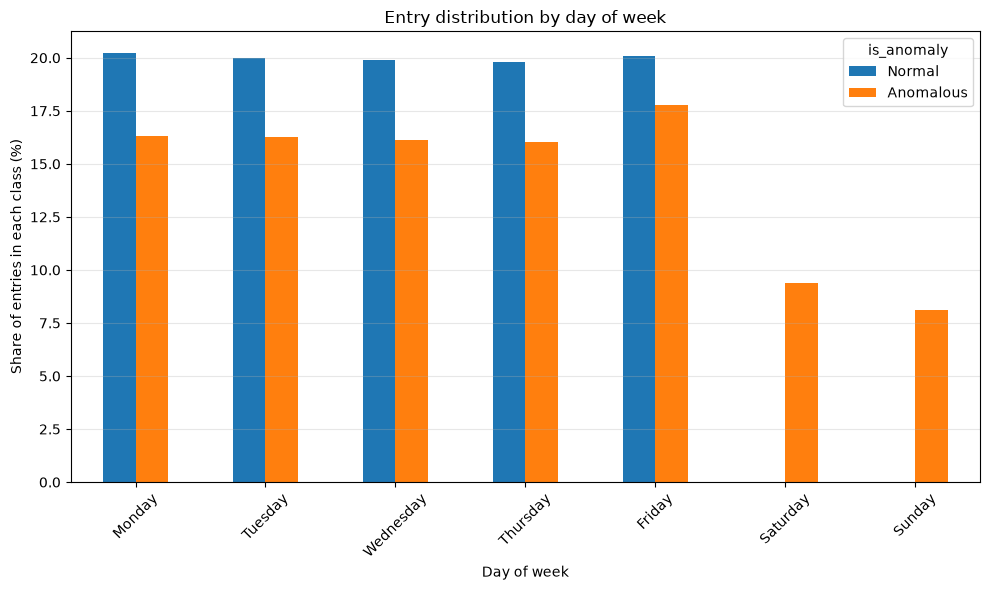

In [180]:

weekday_chart.plot(kind="bar", figsize=(10, 6))
plt.title("Entry distribution by day of week") 
plt.xlabel("Day of week") 
plt.ylabel("Share of entries in each class (%)")
plt.xticks(rotation=45)  
plt.grid(axis="y", alpha=0.3)  
plt.tight_layout() 

Weekend postings distinguish anomalous entries from normal ones in this dataset, though more than one injection type may contribute to that pattern.

## Entry amount distributions

The amount charts compare normal and anomalous entries on linear and logarithmic scales. A few very large amounts stretch the linear axis, making most of the other values look compressed. The logarithmic axis spreads out the smaller and middle-sized values so their distribution is easier to inspect.

The plotted entry amount is the sum of its debit lines. For expense entries, that sum includes both the expense and VAT. The histograms show patterns in the synthetic data; a cluster or unusual amount is not, by itself, evidence of fraud.


In [181]:
normal_amounts = entries.loc[  
    ~entries["is_anomaly"], "total_amount_pence"
].astype(float)  

In [182]:
anomalous_amounts = entries.loc[  
    entries["is_anomaly"], "total_amount_pence"
].astype(float) 

In [183]:
assert (normal_amounts > 0).all()  
assert (anomalous_amounts > 0).all()

In [184]:
log_bins = np.logspace( 
    np.log10(entries["total_amount_pence"].min()),
    np.log10(entries["total_amount_pence"].max()),
    50, 
)

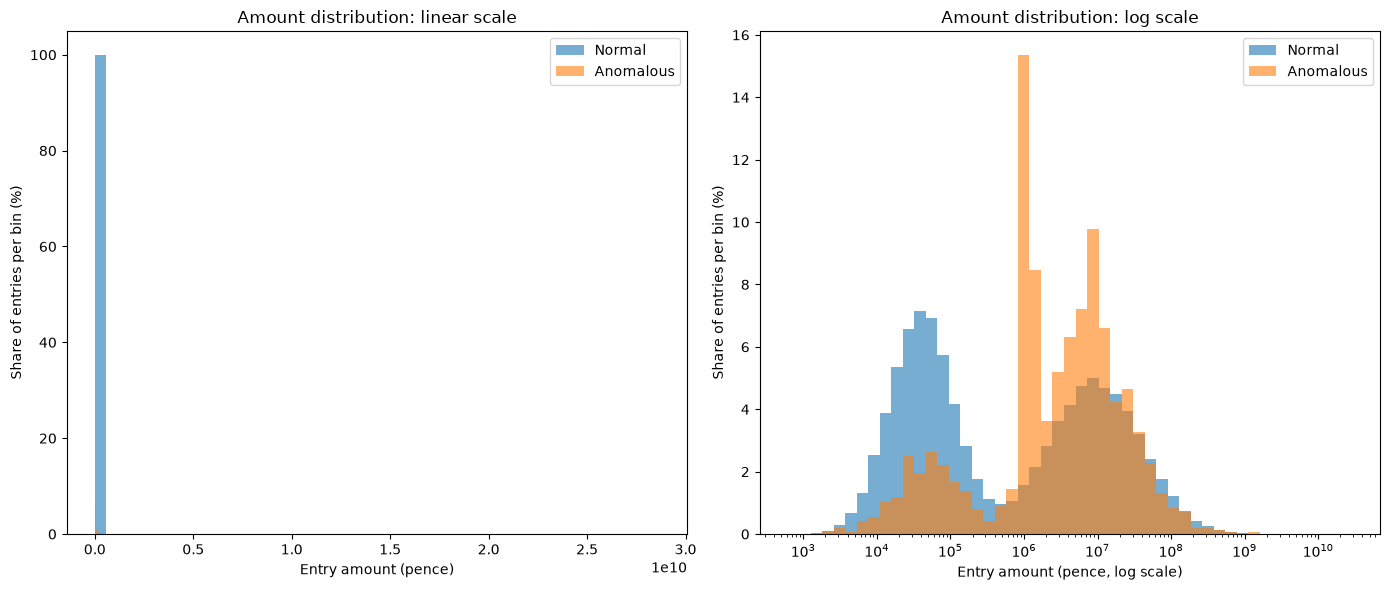

In [185]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].hist(  
    normal_amounts,
    bins=50,
    weights=np.ones(len(normal_amounts)) * 100 / len(normal_amounts),
    alpha=0.6,
    label="Normal",
)
axes[0].hist(  
    anomalous_amounts,
    bins=50,
    weights=np.ones(len(anomalous_amounts)) * 100 / len(anomalous_amounts),
    alpha=0.6,
    label="Anomalous",
)
axes[0].set_title("Amount distribution: linear scale")  
axes[0].set_xlabel("Entry amount (pence)")  
axes[0].set_ylabel("Share of entries per bin (%)")
axes[0].legend()  
axes[1].hist(  
    normal_amounts,
    bins=log_bins,
    weights=np.ones(len(normal_amounts)) * 100 / len(normal_amounts),
    alpha=0.6,
    label="Normal",
)
axes[1].hist(  
    anomalous_amounts,
    bins=log_bins,
    weights=np.ones(len(anomalous_amounts)) * 100 / len(anomalous_amounts),
    alpha=0.6,
    label="Anomalous",
)

axes[1].set_xscale("log")
axes[1].set_title("Amount distribution: log scale")  
axes[1].set_xlabel("Entry amount (pence, log scale)")
axes[1].set_ylabel("Share of entries per bin (%)")
axes[1].legend()  

plt.tight_layout()
plt.show()

## Entries by user

The user chart compares each user's share of normal entries with their share of anomalous entries. Normal entries are spread fairly evenly among users, at about 12.3% to 12.6% per user. The anomalous shares range from about 11.3% to 13.8%. There is no strong separation by user in this chart.


In [186]:
user_counts = (  
    entries.groupby(["user_id", "is_anomaly"])
    .size() 
    .rename("entry_count")  
    .reset_index() 
)

In [187]:
user_counts["percentage"] = ( 
    user_counts["entry_count"]
    / user_counts.groupby("is_anomaly")["entry_count"].transform("sum")
    * 100
)

In [188]:
user_chart = user_counts.pivot(  
    index="user_id",
    columns="is_anomaly",
    values="percentage",
).fillna(0) 

In [189]:
user_chart = user_chart.rename(  
    columns={False: "Normal", True: "Anomalous"}
)

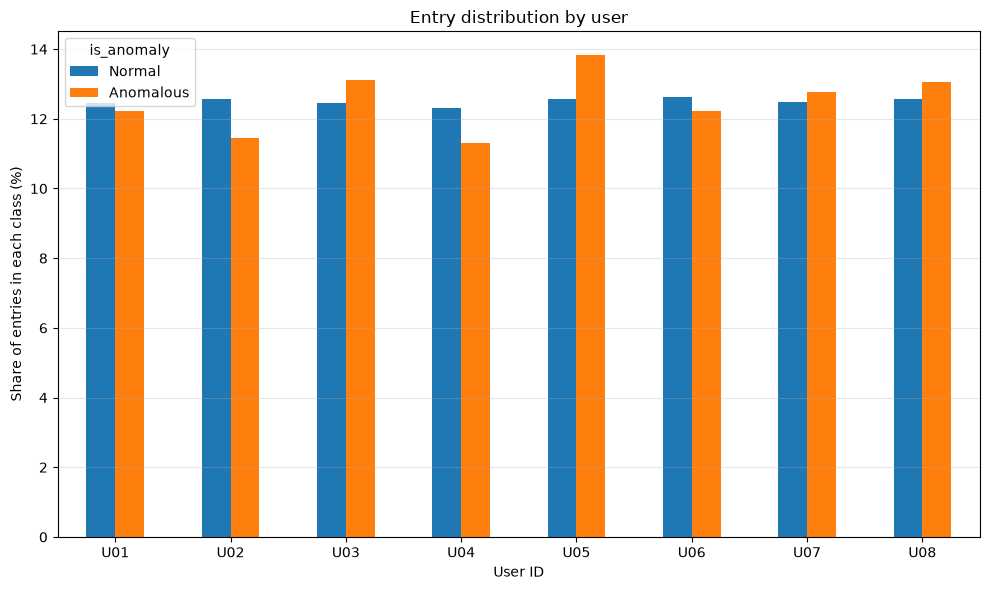

In [190]:
user_chart.plot(kind="bar", figsize=(10, 6))
plt.title("Entry distribution by user")  
plt.xlabel("User ID")  
plt.ylabel("Share of entries in each class (%)")
plt.xticks(rotation=0) 
plt.grid(axis="y", alpha=0.3)  
plt.tight_layout() 
plt.show()  

In [191]:
user_class_counts = (  
    entries.groupby(["user_id", "is_anomaly"])  
    .size()  
    .unstack(fill_value=0)  
    .rename(columns={False: "Normal", True: "Anomalous"})  
)

display(user_class_counts)  

is_anomaly,Normal,Anomalous
user_id,,
U01,22249,176
U02,22476,165
U03,22247,189
U04,22034,163
U05,22457,199
U06,22572,176
U07,22315,184
U08,22480,188


In [192]:
display(user_chart.round(2))

is_anomaly,Normal,Anomalous
user_id,,
U01,12.44,12.22
U02,12.57,11.46
U03,12.44,13.12
U04,12.32,11.32
U05,12.56,13.82
U06,12.62,12.22
U07,12.48,12.78
U08,12.57,13.06


## Entries by posting hour

The hour chart compares each class across all 24 hours. Normal entries appear from 9 a.m. through 5 p.m. Anomalous entries also appear before 6 a.m. and at 10 p.m. or later, matching the odd-timing injection. Other anomaly types can still occur during ordinary working hours.


In [193]:
hour_data = entries.assign(  
    hour=entries["posted_at"].dt.hour
)

hour_counts = (  
    hour_data.groupby(["hour", "is_anomaly"])
    .size()
    .rename("entry_count")
    .reset_index()
)

hour_counts["percentage"] = ( 
    hour_counts["entry_count"]
    / hour_counts.groupby("is_anomaly")["entry_count"].transform("sum")
    * 100
)

hour_chart = hour_counts.pivot(  
    index="hour",
    columns="is_anomaly",
    values="percentage",
).fillna(0)  


hour_chart = hour_chart.reindex(range(24), fill_value=0)
hour_chart = hour_chart.rename(  
    columns={False: "Normal", True: "Anomalous"}
)

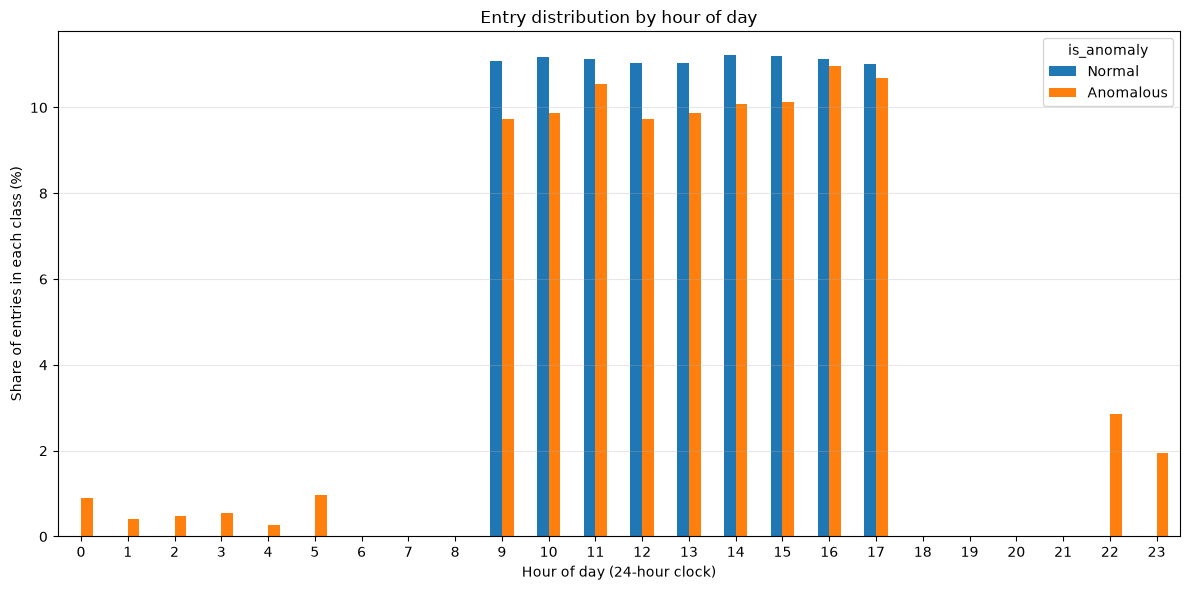

In [194]:

hour_chart.plot(kind="bar", figsize=(12, 6))
plt.title("Entry distribution by hour of day") 
plt.xlabel("Hour of day (24-hour clock)")  
plt.ylabel("Share of entries in each class (%)")
plt.xticks(rotation=0)  
plt.grid(axis="y", alpha=0.3)  
plt.tight_layout()  
plt.show()  

## What the charts show for each anomaly type

### Duplicate payment
A duplicate copies a supplier payment's vendor and accounting lines and posts it one to five days later. The aggregate charts do not directly identify matching vendor-and-amount pairs. Detecting this pattern requires comparing payments by vendor, amount, and date.

### Below-limit amount
A below-limit changes the net expense to between £9,700 and £9,999, then recalculates VAT and payables. Because the plotted total debit includes VAT, these entries appear at roughly £11,640 to £11,998.80 in the amount chart.

### Odd timing
This anomaly moves an entry to a weekend in the same week, or to a weekday before 6 a.m. or at or after 10 p.m. Its pattern is visible in the weekday and hour charts.

### Self-approved entry
A self-approved entry has the same user and approver. None of these four charts compares those two fields, so this anomaly cannot be identified visually from these plots. It requires checking whether `user_id` equals `approver_id`.

### Round-number amount
A round-number anomaly changes a net expense to a multiple of £100 and recalculates VAT. The resulting total debit includes VAT, so the plotted amount is a multiple of £120. These amounts may form clusters in the amount chart.

### Rare account pairing
This rare-pairing anomaly changes the expense account code but leaves the amount unchanged. The charts do not show account codes, so they cannot directly identify unusual account pairings. Also, ordinary expenses currently share the generic description `"Expense"`, which limits how specifically this pairing can be interpreted.